# Imports and EDA

In [34]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split , GridSearchCV 
from sklearn.metrics import accuracy_score, classification_report , confusion_matrix
from sklearn.neighbors import KNeighborsClassifier


import warnings
warnings.filterwarnings('ignore')

In [10]:
df  = pd.read_csv(r"E:\Ai&Machine learning\ASL_landmark_translator\data\processed\asl_features.csv")

In [11]:
df.head()

,label,image_path,tip_4_to_tip_8,tip_4_to_tip_12,tip_4_to_tip_16,tip_4_to_tip_20,tip_8_to_tip_12,tip_8_to_tip_16,tip_8_to_tip_20,tip_12_to_tip_16,...,middle_angle_2,ring_angle_1,ring_angle_2,pinky_angle_1,pinky_angle_2,thumb_straightness,index_straightness,middle_straightness,ring_straightness,pinky_straightness
0,A,E:\Ai&Machine learning\ASL_translator\data\asl...,0.783751,1.003541,1.180855,1.243584,0.267981,0.539913,0.695137,0.290770,...,165.324215,78.676354,159.684056,85.157291,161.909906,0.960596,0.591106,0.620160,0.631236,0.669528
1,A,E:\Ai&Machine learning\ASL_translator\data\asl...,0.737307,0.963463,1.149703,1.221433,0.263878,0.513657,0.658079,0.261643,...,168.613837,91.330585,163.513802,102.626430,162.984731,0.957540,0.530383,0.659472,0.723152,0.763965
2,A,E:\Ai&Machine learning\ASL_translator\data\asl...,0.802613,1.083265,1.341616,1.401673,0.305573,0.600678,0.722993,0.301357,...,163.648958,57.253622,164.445305,43.373412,165.651262,0.981939,0.455219,0.481903,0.538739,0.433389
3,A,E:\Ai&Machine learning\ASL_translator\data\asl...,0.664505,0.911718,1.074565,1.155403,0.267314,0.489825,0.616182,0.246852,...,167.467029,69.398124,162.862546,90.903116,162.964296,0.959748,0.554256,0.620367,0.591500,0.700189
4,A,E:\Ai&Machine learning\ASL_translator\data\asl...,0.696344,0.955344,1.113713,1.200178,0.278967,0.497142,0.628632,0.244563,...,166.452259,62.119928,162.043729,79.797936,163.548211,0.962633,0.545351,0.572110,0.537161,0.642473


In [12]:
df = df.drop(columns=["image_path"])

In [13]:
df.head()

,label,tip_4_to_tip_8,tip_4_to_tip_12,tip_4_to_tip_16,tip_4_to_tip_20,tip_8_to_tip_12,tip_8_to_tip_16,tip_8_to_tip_20,tip_12_to_tip_16,tip_12_to_tip_20,...,middle_angle_2,ring_angle_1,ring_angle_2,pinky_angle_1,pinky_angle_2,thumb_straightness,index_straightness,middle_straightness,ring_straightness,pinky_straightness
0,A,0.783751,1.003541,1.180855,1.243584,0.267981,0.539913,0.695137,0.290770,0.468128,...,165.324215,78.676354,159.684056,85.157291,161.909906,0.960596,0.591106,0.620160,0.631236,0.669528
1,A,0.737307,0.963463,1.149703,1.221433,0.263878,0.513657,0.658079,0.261643,0.442144,...,168.613837,91.330585,163.513802,102.626430,162.984731,0.957540,0.530383,0.659472,0.723152,0.763965
2,A,0.802613,1.083265,1.341616,1.401673,0.305573,0.600678,0.722993,0.301357,0.449732,...,163.648958,57.253622,164.445305,43.373412,165.651262,0.981939,0.455219,0.481903,0.538739,0.433389
3,A,0.664505,0.911718,1.074565,1.155403,0.267314,0.489825,0.616182,0.246852,0.396883,...,167.467029,69.398124,162.862546,90.903116,162.964296,0.959748,0.554256,0.620367,0.591500,0.700189
4,A,0.696344,0.955344,1.113713,1.200178,0.278967,0.497142,0.628632,0.244563,0.395777,...,166.452259,62.119928,162.043729,79.797936,163.548211,0.962633,0.545351,0.572110,0.537161,0.642473


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55367 entries, 0 to 55366
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   label                55367 non-null  str    
 1   tip_4_to_tip_8       55367 non-null  float64
 2   tip_4_to_tip_12      55367 non-null  float64
 3   tip_4_to_tip_16      55367 non-null  float64
 4   tip_4_to_tip_20      55367 non-null  float64
 5   tip_8_to_tip_12      55367 non-null  float64
 6   tip_8_to_tip_16      55367 non-null  float64
 7   tip_8_to_tip_20      55367 non-null  float64
 8   tip_12_to_tip_16     55367 non-null  float64
 9   tip_12_to_tip_20     55367 non-null  float64
 10  tip_16_to_tip_20     55367 non-null  float64
 11  wrist_to_tip_4       55367 non-null  float64
 12  wrist_to_tip_8       55367 non-null  float64
 13  wrist_to_tip_12      55367 non-null  float64
 14  wrist_to_tip_16      55367 non-null  float64
 15  wrist_to_tip_20      55367 non-null  float64
 1

In [15]:
df.describe()

,tip_4_to_tip_8,tip_4_to_tip_12,tip_4_to_tip_16,tip_4_to_tip_20,tip_8_to_tip_12,tip_8_to_tip_16,tip_8_to_tip_20,tip_12_to_tip_16,tip_12_to_tip_20,tip_16_to_tip_20,...,middle_angle_2,ring_angle_1,ring_angle_2,pinky_angle_1,pinky_angle_2,thumb_straightness,index_straightness,middle_straightness,ring_straightness,pinky_straightness
count,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,...,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000,55367.000000
mean,0.820978,0.789789,0.754973,0.883388,0.525579,0.920699,1.150822,0.553453,0.863779,0.384361,...,164.741529,84.448726,160.147066,92.892584,161.512520,0.873864,0.850401,0.742183,0.596339,0.638545
std,0.380372,0.377332,0.411330,0.483629,0.397758,0.457408,0.427130,0.496726,0.497406,0.336414,...,11.462835,47.550035,11.204090,52.509960,11.673713,0.110659,0.228800,0.261404,0.247158,0.261385
min,0.016462,0.015717,0.018191,0.014329,0.010024,0.010912,0.031837,0.004568,0.010149,0.007056,...,11.882347,0.866958,13.538237,0.489326,28.478537,0.504461,0.089731,0.053530,0.031169,0.019546
25%,0.514109,0.409361,0.408347,0.496788,0.235277,0.478522,0.750476,0.219540,0.452397,0.197949,...,161.291487,47.470374,155.833739,47.490278,157.255641,0.787672,0.794132,0.495123,0.412069,0.417504
50%,0.871423,0.874984,0.638649,0.758777,0.345407,0.946685,1.217764,0.295361,0.575569,0.235197,...,168.037653,63.228580,161.756253,72.893320,163.887194,0.906441,0.990108,0.823687,0.505076,0.570696
75%,1.077959,1.096072,1.091713,1.251890,0.719571,1.321774,1.503795,0.652714,1.368013,0.336014,...,171.784470,126.101451,166.895108,146.238965,168.478626,0.973979,0.997346,0.995264,0.836114,0.924002
max,3.609993,3.805284,4.110594,4.490535,3.615130,4.005621,4.074578,2.068174,2.484253,1.563002,...,179.944048,179.618142,179.859087,179.913538,179.929185,0.999951,0.999990,0.999941,0.999920,0.999992


In [16]:
df.isna().sum()

label                  0
tip_4_to_tip_8         0
tip_4_to_tip_12        0
tip_4_to_tip_16        0
tip_4_to_tip_20        0
tip_8_to_tip_12        0
tip_8_to_tip_16        0
tip_8_to_tip_20        0
tip_12_to_tip_16       0
tip_12_to_tip_20       0
tip_16_to_tip_20       0
wrist_to_tip_4         0
wrist_to_tip_8         0
wrist_to_tip_12        0
wrist_to_tip_16        0
wrist_to_tip_20        0
thumb_angle_1          0
thumb_angle_2          0
index_angle_1          0
index_angle_2          0
middle_angle_1         0
middle_angle_2         0
ring_angle_1           0
ring_angle_2           0
pinky_angle_1          0
pinky_angle_2          0
thumb_straightness     0
index_straightness     0
middle_straightness    0
ring_straightness      0
pinky_straightness     0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.head()

,label,tip_4_to_tip_8,tip_4_to_tip_12,tip_4_to_tip_16,tip_4_to_tip_20,tip_8_to_tip_12,tip_8_to_tip_16,tip_8_to_tip_20,tip_12_to_tip_16,tip_12_to_tip_20,...,middle_angle_2,ring_angle_1,ring_angle_2,pinky_angle_1,pinky_angle_2,thumb_straightness,index_straightness,middle_straightness,ring_straightness,pinky_straightness
0,A,0.783751,1.003541,1.180855,1.243584,0.267981,0.539913,0.695137,0.290770,0.468128,...,165.324215,78.676354,159.684056,85.157291,161.909906,0.960596,0.591106,0.620160,0.631236,0.669528
1,A,0.737307,0.963463,1.149703,1.221433,0.263878,0.513657,0.658079,0.261643,0.442144,...,168.613837,91.330585,163.513802,102.626430,162.984731,0.957540,0.530383,0.659472,0.723152,0.763965
2,A,0.802613,1.083265,1.341616,1.401673,0.305573,0.600678,0.722993,0.301357,0.449732,...,163.648958,57.253622,164.445305,43.373412,165.651262,0.981939,0.455219,0.481903,0.538739,0.433389
3,A,0.664505,0.911718,1.074565,1.155403,0.267314,0.489825,0.616182,0.246852,0.396883,...,167.467029,69.398124,162.862546,90.903116,162.964296,0.959748,0.554256,0.620367,0.591500,0.700189
4,A,0.696344,0.955344,1.113713,1.200178,0.278967,0.497142,0.628632,0.244563,0.395777,...,166.452259,62.119928,162.043729,79.797936,163.548211,0.962633,0.545351,0.572110,0.537161,0.642473


In [19]:
df['label'].value_counts()

label
F    2864
K    2699
Y    2580
S    2555
V    2548
R    2545
L    2521
U    2509
D    2457
W    2453
G    2428
I    2379
H    2373
T    2354
E    2307
O    2258
B    2202
A    2182
X    2155
Q    2118
P    2040
C    1962
M    1603
N    1275
Name: count, dtype: int64

# Preprocessing for the Model

## Train and test split

In [61]:
x = df.drop(columns=["label"])
y = df['label']

In [62]:
x.head()

,tip_4_to_tip_8,tip_4_to_tip_12,tip_4_to_tip_16,tip_4_to_tip_20,tip_8_to_tip_12,tip_8_to_tip_16,tip_8_to_tip_20,tip_12_to_tip_16,tip_12_to_tip_20,tip_16_to_tip_20,...,middle_angle_2,ring_angle_1,ring_angle_2,pinky_angle_1,pinky_angle_2,thumb_straightness,index_straightness,middle_straightness,ring_straightness,pinky_straightness
0,0.783751,1.003541,1.180855,1.243584,0.267981,0.539913,0.695137,0.290770,0.468128,0.218501,...,165.324215,78.676354,159.684056,85.157291,161.909906,0.960596,0.591106,0.620160,0.631236,0.669528
1,0.737307,0.963463,1.149703,1.221433,0.263878,0.513657,0.658079,0.261643,0.442144,0.226242,...,168.613837,91.330585,163.513802,102.626430,162.984731,0.957540,0.530383,0.659472,0.723152,0.763965
2,0.802613,1.083265,1.341616,1.401673,0.305573,0.600678,0.722993,0.301357,0.449732,0.234988,...,163.648958,57.253622,164.445305,43.373412,165.651262,0.981939,0.455219,0.481903,0.538739,0.433389
3,0.664505,0.911718,1.074565,1.155403,0.267314,0.489825,0.616182,0.246852,0.396883,0.187138,...,167.467029,69.398124,162.862546,90.903116,162.964296,0.959748,0.554256,0.620367,0.591500,0.700189
4,0.696344,0.955344,1.113713,1.200178,0.278967,0.497142,0.628632,0.244563,0.395777,0.183096,...,166.452259,62.119928,162.043729,79.797936,163.548211,0.962633,0.545351,0.572110,0.537161,0.642473


In [63]:
y.head()

0    A
1    A
2    A
3    A
4    A
Name: label, dtype: str

In [64]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42 , stratify=y)

In [65]:
x_train.head()

,tip_4_to_tip_8,tip_4_to_tip_12,tip_4_to_tip_16,tip_4_to_tip_20,tip_8_to_tip_12,tip_8_to_tip_16,tip_8_to_tip_20,tip_12_to_tip_16,tip_12_to_tip_20,tip_16_to_tip_20,...,middle_angle_2,ring_angle_1,ring_angle_2,pinky_angle_1,pinky_angle_2,thumb_straightness,index_straightness,middle_straightness,ring_straightness,pinky_straightness
37981,1.000044,1.083887,0.387528,0.442199,0.089438,1.317808,1.416924,1.396072,1.497352,0.137497,...,168.734623,59.393180,154.177204,45.617624,164.713074,0.861151,0.997367,0.996108,0.439251,0.409054
8492,1.310453,0.294973,0.315313,0.522221,1.122976,1.249026,1.080112,0.141602,0.252990,0.269691,...,154.842830,90.976032,153.103645,111.083360,152.117712,0.968193,0.996074,0.642467,0.632804,0.748720
37426,0.891078,0.987788,0.367816,0.425261,0.126678,1.238982,1.315574,1.342475,1.411389,0.173424,...,173.174121,51.890821,156.011272,54.771565,158.048525,0.815484,0.995370,0.996187,0.386729,0.402827
44289,1.183791,1.184752,0.430164,0.541354,0.307110,1.358189,1.561376,1.408909,1.608099,0.208591,...,170.742195,56.882318,158.740583,72.923392,164.485086,0.695669,0.998504,0.997620,0.439607,0.598534
44410,1.231981,1.260408,0.337603,0.428356,0.293312,1.435899,1.615947,1.478554,1.644473,0.209938,...,170.543720,57.374308,157.566963,68.028988,158.599172,0.697847,0.999201,0.997917,0.428435,0.511473


In [66]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 44293 entries, 37981 to 28405
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tip_4_to_tip_8       44293 non-null  float64
 1   tip_4_to_tip_12      44293 non-null  float64
 2   tip_4_to_tip_16      44293 non-null  float64
 3   tip_4_to_tip_20      44293 non-null  float64
 4   tip_8_to_tip_12      44293 non-null  float64
 5   tip_8_to_tip_16      44293 non-null  float64
 6   tip_8_to_tip_20      44293 non-null  float64
 7   tip_12_to_tip_16     44293 non-null  float64
 8   tip_12_to_tip_20     44293 non-null  float64
 9   tip_16_to_tip_20     44293 non-null  float64
 10  wrist_to_tip_4       44293 non-null  float64
 11  wrist_to_tip_8       44293 non-null  float64
 12  wrist_to_tip_12      44293 non-null  float64
 13  wrist_to_tip_16      44293 non-null  float64
 14  wrist_to_tip_20      44293 non-null  float64
 15  thumb_angle_1        44293 non-null  float64
 16

In [59]:
standard = StandardScaler()
x_train = standard.fit_transform(x_train)
x_test = standard.transform(x_test)

# Training KNN model

## vanilla model

### training model

In [29]:
knn_model_vanilla = KNeighborsClassifier()
knn_model_vanilla.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](24,)","['A','B','C',...,'W','X','Y']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### model evaluation

In [31]:
y_pred_vanilla = knn_model_vanilla.predict(x_test)

In [42]:
y_pred_train = knn_model_vanilla.predict(x_train)

In [44]:
print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           A       0.97      0.99      0.98      1746
           B       1.00      1.00      1.00      1762
           C       0.97      0.99      0.98      1570
           D       0.97      0.98      0.98      1966
           E       0.99      0.98      0.99      1846
           F       1.00      0.99      1.00      2291
           G       0.98      0.98      0.98      1942
           H       0.97      0.96      0.97      1898
           I       1.00      0.98      0.99      1903
           K       0.99      0.99      0.99      2159
           L       1.00      1.00      1.00      2017
           M       0.89      0.97      0.93      1283
           N       0.95      0.89      0.92      1020
           O       0.96      0.99      0.98      1806
           P       0.99      0.98      0.98      1632
           Q       0.98      0.98      0.98      1694
           R       0.97      0.98      0.97      2036
           S       0.99    

In [33]:
print(classification_report(y_test, y_pred_vanilla))

              precision    recall  f1-score   support

           A       0.95      0.98      0.96       436
           B       1.00      1.00      1.00       440
           C       0.94      0.99      0.97       392
           D       0.97      0.98      0.97       491
           E       0.99      0.97      0.98       461
           F       0.99      1.00      0.99       573
           G       0.97      0.97      0.97       486
           H       0.95      0.93      0.94       475
           I       0.99      0.95      0.97       476
           K       0.99      0.99      0.99       540
           L       1.00      0.99      0.99       504
           M       0.85      0.95      0.90       320
           N       0.94      0.85      0.89       255
           O       0.95      0.98      0.97       452
           P       0.99      0.98      0.98       408
           Q       0.98      0.97      0.97       424
           R       0.96      0.98      0.97       509
           S       0.98    

In [35]:
confusion_matrix = pd.crosstab(y_test, y_pred_vanilla, rownames=['Actual'], colnames=['Predicted'])

<Axes: xlabel='Predicted', ylabel='Actual'>

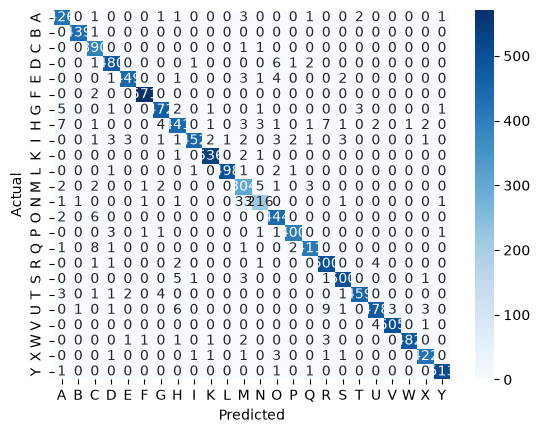

In [37]:
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')

## Best Model


In [38]:
acc= []
for k in range(1,30):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train,y_train)
    y_pred = knn.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    acc.append(accuracy)
    print(f'k={k} , accuracy={accuracy}')

k=1 , accuracy=0.9792306303052194
k=2 , accuracy=0.9750767563662633
k=3 , accuracy=0.9776052013725844
k=4 , accuracy=0.9744446451146831
k=5 , accuracy=0.9741737402925772
k=6 , accuracy=0.9729095177894167
k=7 , accuracy=0.9729998193967853
k=8 , accuracy=0.9718258985009933
k=9 , accuracy=0.9713743904641503
k=10 , accuracy=0.9703810727830955
k=11 , accuracy=0.9700198663536211
k=12 , accuracy=0.9685750406357233
k=13 , accuracy=0.9685750406357233
k=14 , accuracy=0.9676720245620372
k=15 , accuracy=0.9666787068809825
k=16 , accuracy=0.9664078020588767
k=17 , accuracy=0.9657756908072964
k=18 , accuracy=0.9653241827704533
k=19 , accuracy=0.9651435795557161
k=20 , accuracy=0.9648726747336103
k=21 , accuracy=0.9644211666967673
k=22 , accuracy=0.9636987538378183
k=23 , accuracy=0.9628860393715009
k=24 , accuracy=0.9621636265125519
k=25 , accuracy=0.961441213653603
k=26 , accuracy=0.9615315152609717
k=27 , accuracy=0.96098970561676
k=28 , accuracy=0.9611703088314972
k=29 , accuracy=0.96089940400939

In [41]:
max_acc = max(acc)
print(f'Maximum accuracy is {max_acc} at k={acc.index(max_acc)+1}')


Maximum accuracy is 0.9792306303052194 at k=1


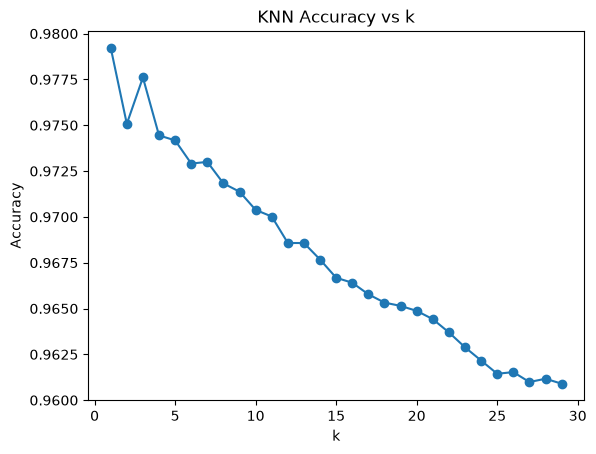

In [45]:
plt.plot(range(1,30),acc,marker='o')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs k')
plt.show()

### Best model at k=3

In [47]:
knn_best = KNeighborsClassifier(n_neighbors=3)
knn_best.fit(x_train, y_train)
y_pred_best = knn_best.predict(x_test)
accuracy_best = accuracy_score(y_test, y_pred_best)
print(f'Best KNN model accuracy with k=3: {accuracy_best}')

Best KNN model accuracy with k=3: 0.9776052013725844


In [49]:
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           A       0.96      0.98      0.97       436
           B       0.99      1.00      0.99       440
           C       0.96      0.99      0.97       392
           D       0.97      0.98      0.98       491
           E       0.99      0.98      0.98       461
           F       0.99      1.00      1.00       573
           G       0.97      0.98      0.98       486
           H       0.95      0.94      0.95       475
           I       0.99      0.96      0.97       476
           K       0.99      0.99      0.99       540
           L       1.00      0.99      1.00       504
           M       0.86      0.94      0.90       320
           N       0.94      0.86      0.90       255
           O       0.96      0.98      0.97       452
           P       0.99      0.98      0.99       408
           Q       0.99      0.97      0.98       424
           R       0.96      0.98      0.97       509
           S       0.99    

## Pipelined model

In [73]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        metric="euclidean"
    ))
])

In [74]:
knn_pipeline = knn_pipeline.fit(x_train, y_train)

In [ ]:
y_pred_pipeline = knn_pipeline.predict(x_test)

In [80]:
print(classification_report(y_test, y_pred_pipeline))

              precision    recall  f1-score   support

           A       0.95      0.98      0.96       436
           B       1.00      1.00      1.00       440
           C       0.94      0.99      0.97       392
           D       0.97      0.98      0.97       491
           E       0.99      0.97      0.98       461
           F       0.99      1.00      0.99       573
           G       0.97      0.97      0.97       486
           H       0.95      0.93      0.94       475
           I       0.99      0.95      0.97       476
           K       0.99      0.99      0.99       540
           L       1.00      0.99      0.99       504
           M       0.85      0.95      0.90       320
           N       0.94      0.85      0.89       255
           O       0.95      0.98      0.97       452
           P       0.99      0.98      0.98       408
           Q       0.98      0.97      0.97       424
           R       0.96      0.98      0.97       509
           S       0.98    

# Saving model

In [81]:
import joblib
import os

os.makedirs("models", exist_ok=True)

model_bundle = {
    "model": knn_pipeline,
    "feature_columns": x.columns.tolist()
}

joblib.dump(
    model_bundle,
    "models/asl_knn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
